# Problem 7.6 — K–R Curve from a Compact Specimen Test

A compact tension (CT) specimen of 5 mm thick aluminum sheet is tested:

| Parameter | Value |
|---|---|
| Width $W$ | 50.0 mm |
| Thickness $B$ | 5 mm |
| Initial crack length $a_0$ | 26.0 mm |
| Young's modulus $E$ | 70,000 MPa |

**Assumption:** all nonlinearity in the $P$–$\Delta$ curve is due to crack growth. So the secant compliance $C = \Delta/P$ at each point is an *elastic* compliance, which gives the current crack length $a$. With $a$ known, $K$ follows from the CT stress-intensity solution.

## Equations (Anderson, Appendix A7, compact specimen)

**Crack length from load-line compliance:**

$$\frac{a}{W} = 1.000196 - 4.06319\,u + 11.242\,u^2 - 106.043\,u^3 + 464.335\,u^4 - 650.677\,u^5$$

$$u = \frac{1}{\sqrt{B\,E'\,C} + 1}$$

The sheet is thin, so we assume plane stress: $E' = E$.

**Stress intensity:**

$$K_I = \frac{P}{B\sqrt{W}}\, f\!\left(\frac{a}{W}\right),\qquad
f\!\left(\frac{a}{W}\right)=\frac{2+\frac{a}{W}}{\left(1-\frac{a}{W}\right)^{3/2}}
\left[0.886 + 4.64\frac{a}{W} - 13.32\left(\frac{a}{W}\right)^2 + 14.72\left(\frac{a}{W}\right)^3 - 5.6\left(\frac{a}{W}\right)^4\right]$$


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Specimen and material properties (units: N, mm, MPa)
W  = 50.0       # mm
B  = 5.0        # mm
a0 = 26.0       # mm
E  = 70_000.0   # MPa
E_prime = E     # plane stress (thin sheet)

## Test data

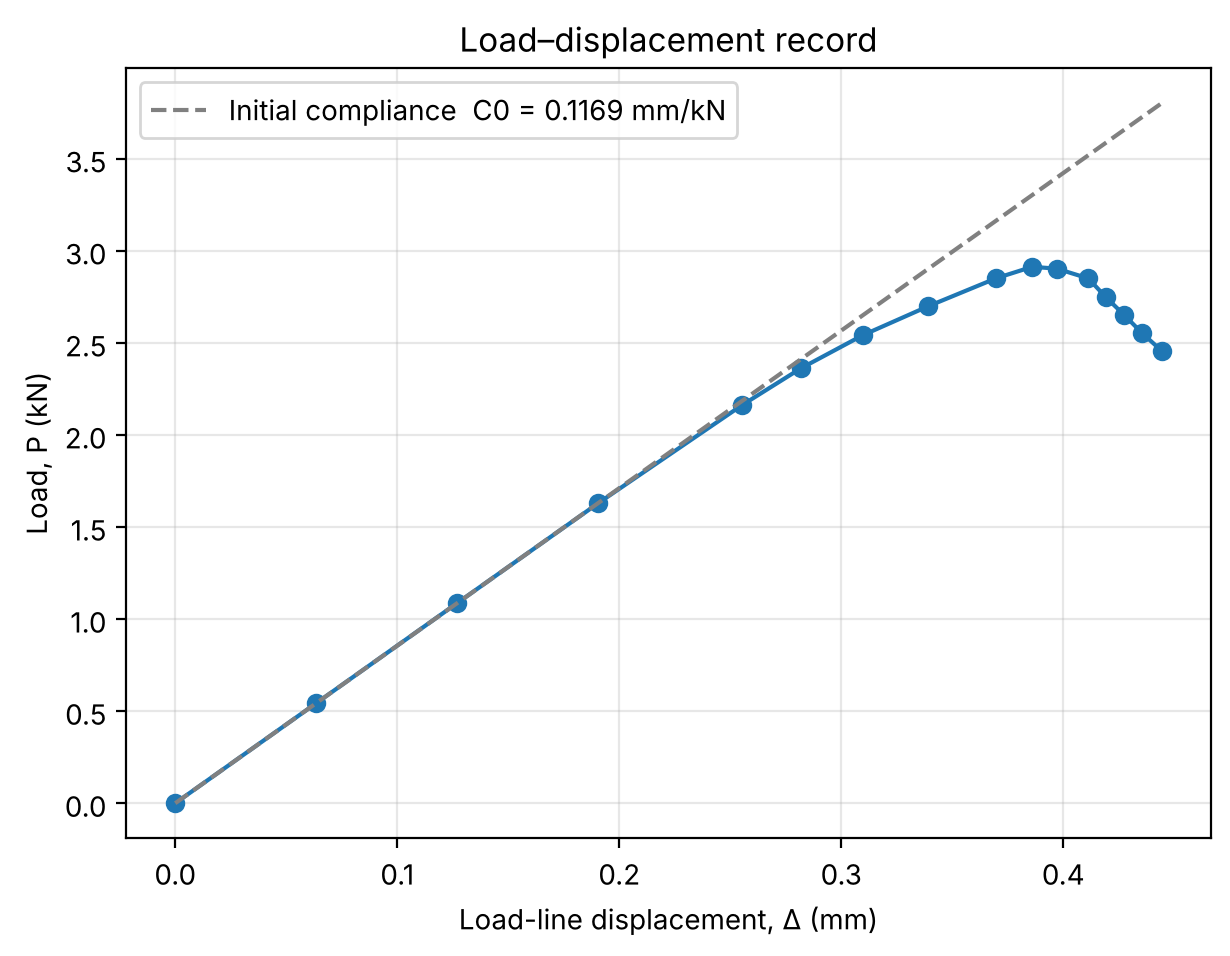

In [2]:
P_kN = np.array([0, 0.5433, 1.087, 1.630, 2.161, 2.361, 2.541, 2.699,
                 2.851, 2.913, 2.903, 2.850, 2.749, 2.652, 2.553, 2.457])
disp_mm = np.array([0, 0.0635, 0.1270, 0.1906, 0.2552, 0.2817, 0.3096, 0.3392,
                    0.3698, 0.3860, 0.3971, 0.4113, 0.4191, 0.4274, 0.4355, 0.4443])

P = P_kN * 1000.0   # N

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(disp_mm, P_kN, 'o-', color='tab:blue')
# initial elastic line, for reference
C0 = disp_mm[1] / P_kN[1]   # mm/kN
x = np.linspace(0, disp_mm.max(), 50)
ax.plot(x, x / C0, '--', color='gray', label=f'Initial compliance  C0 = {C0:.4f} mm/kN')
ax.set_xlabel('Load-line displacement, Δ (mm)')
ax.set_ylabel('Load, P (kN)')
ax.set_title('Load–displacement record')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Compliance and stress-intensity functions (Appendix A7)

In [3]:
def a_over_W_from_compliance(C, B=B, E_prime=E_prime):
    """Crack length ratio a/W from load-line compliance C (mm/N)."""
    u = 1.0 / (np.sqrt(B * E_prime * C) + 1.0)
    return (1.000196 - 4.06319*u + 11.242*u**2 - 106.043*u**3
            + 464.335*u**4 - 650.677*u**5)

def f_CT(aW):
    """Geometry factor for the compact specimen."""
    return ((2 + aW) / (1 - aW)**1.5 *
            (0.886 + 4.64*aW - 13.32*aW**2 + 14.72*aW**3 - 5.6*aW**4))

def K_CT(P, a, B=B, W=W):
    """K in MPa*sqrt(m). P in N, a in mm."""
    K_mm = P / (B * np.sqrt(W)) * f_CT(a / W)   # MPa*sqrt(mm)
    return K_mm / np.sqrt(1000.0)                 # MPa*sqrt(m)

### Check: does the initial compliance reproduce $a_0 = 26.0$ mm?

The first data points lie on the elastic line, so their compliance should give back the starting crack length.

In [4]:
C_initial = disp_mm[1] / P[1]   # mm/N
a_check = a_over_W_from_compliance(C_initial) * W
print(f'Initial compliance  = {C_initial:.4e} mm/N')
print(f'Predicted a0        = {a_check:.2f} mm   (given: {a0} mm)')

Initial compliance  = 1.1688e-04 mm/N
Predicted a0        = 26.00 mm   (given: 26.0 mm)


## Compute the K–R curve

For each data point (skipping $P = 0$):
1. Secant compliance $C = \Delta / P$
2. Crack length $a$ from the compliance equation
3. Crack extension $\Delta a = a - a_0$ (using the given $a_0$; tiny negative values in the linear region are set to 0)
4. $K_R = K(P, a)$

In [5]:
mask = P > 0
C  = disp_mm[mask] / P[mask]                 # mm/N
a  = a_over_W_from_compliance(C) * W         # mm
da = np.clip(a - a0, 0, None)                # mm
K  = K_CT(P[mask], a)                        # MPa*sqrt(m)

results = pd.DataFrame({
    'P (kN)': P_kN[mask],
    'Δ (mm)': disp_mm[mask],
    'C (mm/kN)': C * 1000,
    'a (mm)': a,
    'Δa (mm)': da,
    'a/W': a / W,
    'K_R (MPa√m)': K,
    'K_R (ksi√in)': K * 0.910,   # 1 MPa√m = 0.910 ksi√in
})
results.round(4)

,P (kN),Δ (mm),C (mm/kN),a (mm),Δa (mm),a/W,K_R (MPa√m),K_R (ksi√in)
0,0.5433,0.0635,0.1169,25.9998,0.0000,0.5200,4.9982,4.5484
1,1.0870,0.1270,0.1168,25.9962,0.0000,0.5199,9.9979,9.0981
2,1.6300,0.1906,0.1169,26.0043,0.0043,0.5201,15.0000,13.6500
3,2.1610,0.2552,0.1181,26.1005,0.1005,0.5220,20.0100,18.2091
4,2.3610,0.2817,0.1193,26.2004,0.2004,0.5240,22.0035,20.0232
5,2.5410,0.3096,0.1218,26.4031,0.4031,0.5281,23.9957,21.8361
6,2.6990,0.3392,0.1257,26.7007,0.7007,0.5340,25.9920,23.6527
7,2.8510,0.3698,0.1297,27.0014,1.0014,0.5400,28.0126,25.4914
8,2.9130,0.3860,0.1325,27.2033,1.2033,0.5441,29.0147,26.4034
9,2.9030,0.3971,0.1368,27.5014,1.5014,0.5500,29.5105,26.8545


## Plot the K–R curve

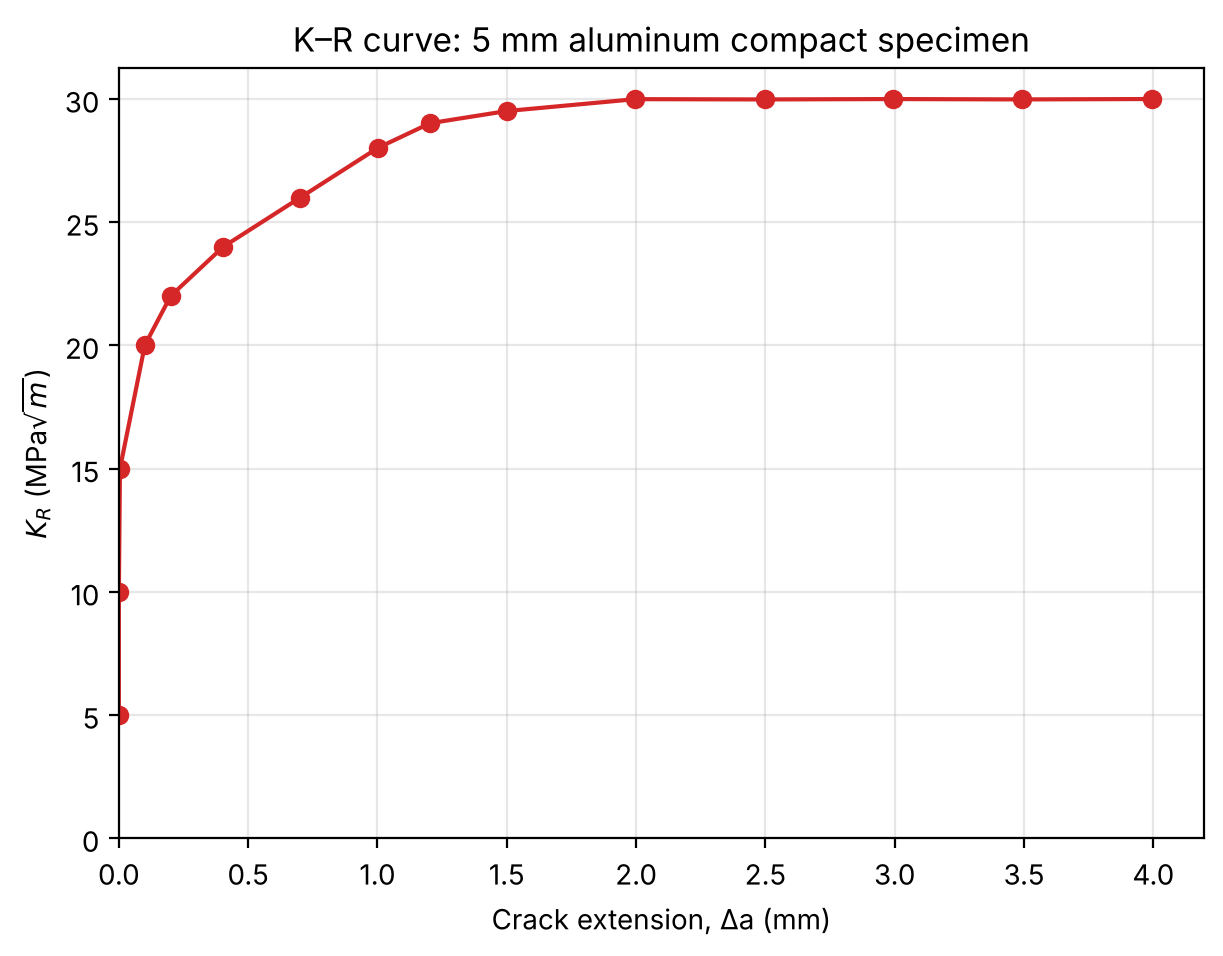

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(da, K, 'o-', color='tab:red')
ax.set_xlabel('Crack extension, Δa (mm)')
ax.set_ylabel(r'$K_R$ (MPa$\sqrt{m}$)')
ax.set_title('K–R curve: 5 mm aluminum compact specimen')
ax.grid(alpha=0.3)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
plt.show()

### Side by side: load record and K–R curve

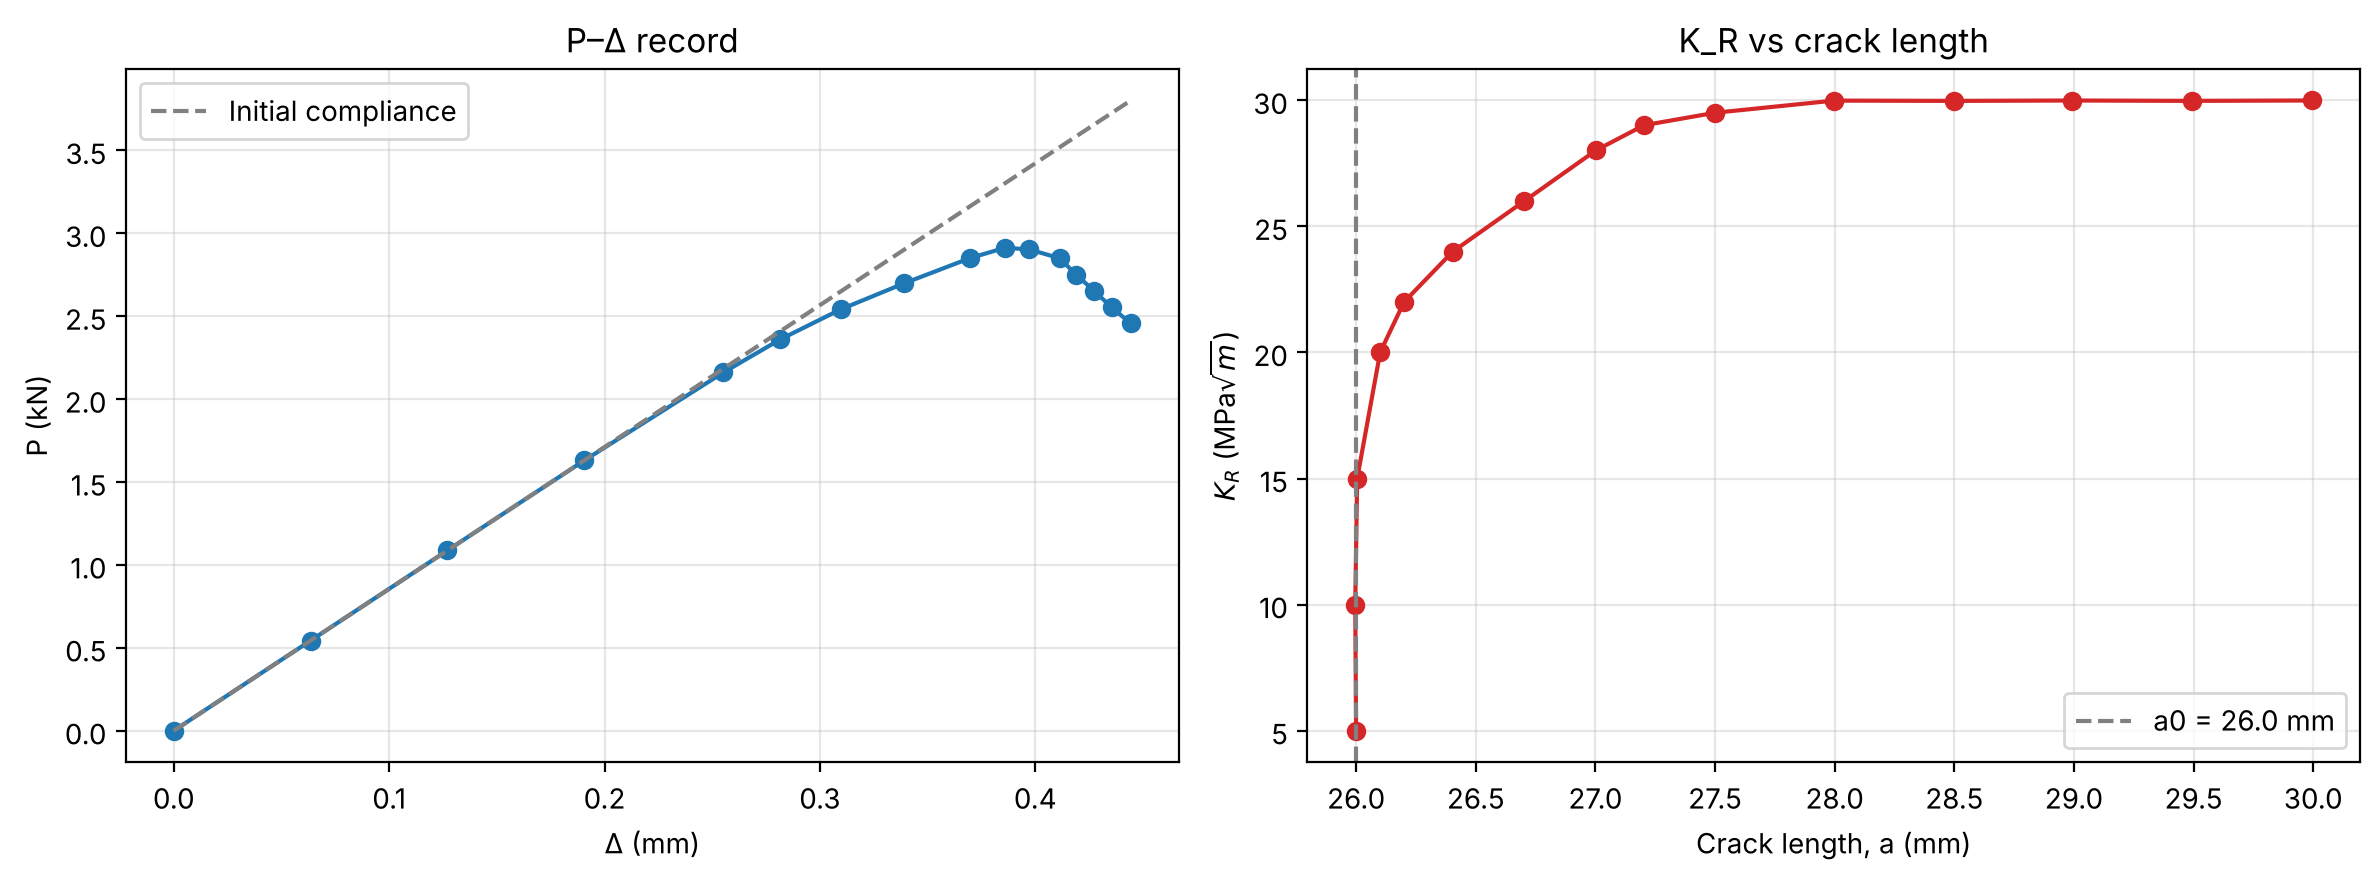

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(disp_mm, P_kN, 'o-', color='tab:blue')
ax1.plot(x, x / C0, '--', color='gray', label='Initial compliance')
ax1.set_xlabel('Δ (mm)'); ax1.set_ylabel('P (kN)')
ax1.set_title('P–Δ record'); ax1.grid(alpha=0.3); ax1.legend()

ax2.plot(a, K, 'o-', color='tab:red')
ax2.axvline(a0, color='gray', ls='--', label=f'a0 = {a0} mm')
ax2.set_xlabel('Crack length, a (mm)'); ax2.set_ylabel(r'$K_R$ (MPa$\sqrt{m}$)')
ax2.set_title('K_R vs crack length'); ax2.grid(alpha=0.3); ax2.legend()

plt.tight_layout()
plt.show()

## Notes

- Up to about 2.1 kN the secant compliance stays constant, so $a \approx a_0$: no crack growth in the linear part.
- As the curve bends over, compliance rises and the crack grows. $K_R$ rises steeply over the first ~1.5 mm of crack extension, then levels off at a plateau of about **30 MPa$\sqrt{m}$** (≈ 27 ksi$\sqrt{in}$) for $\Delta a \gtrsim 2$ mm. That flat part is steady-state crack growth. Past peak load the crack keeps growing at constant $K_R$, so the load falls.
- Treating all nonlinearity as crack growth ignores plasticity. That makes $\Delta a$ an *effective* crack extension, roughly physical crack growth plus a plastic-zone correction.